# 03 · Multi-agent simulation and scenarios

**Goal:** create a population of consumer agents from the personas, let them judge a product and influence each other, and compare launch scenarios (discount, price rise, marketing, competitor price cut).

### How the model works (and why)
1. **Agents.** 400 agents are sampled from the personas by their share. Each gets aspect weights (the persona's weights with random noise), a susceptibility to peers, an influence weight (influencers count 3×, reviewers 1.5×) and a "top concern".
   *Why:* heterogeneity is the central idea of the project; noise stops all agents of a persona being identical.
2. **Judging a product.** An agent compares the product's real aspect satisfaction (from reviews) with the category average, weighted by what that agent cares about, and adds the persona's baseline.
   *Why:* it makes the product's actual review profile matter, in a way we can explain.
3. **Shrinkage.** Product satisfaction is pulled toward the category mean when a product has few mentions: `(n·mean + 10·category_mean) / (n + 10)`.
   *Why:* a product with three "battery" mentions would otherwise get an extreme, noisy score.
4. **Logistic decision rule.** Opinions live in logit space and are turned into a probability with a sigmoid.
   *Why:* bounded between 0 and 1, smooth, and every term has a plain meaning.
5. **Scenario terms.** Price enters as `−elasticity × log(price multiplier)` (a standard constant-elasticity form); marketing adds a boost for agents who are open to it; a competitor price cut pulls agents who like the competitor.
   *These effect sizes are ASSUMED* (price elasticity 2.5, marketing boost 0.5, competitor switching 2.0) because the review data contains no prices or sales.
6. **Peer influence.** Over 5 rounds agents move toward the influence-weighted crowd opinion and toward the evidence they retrieved.
   *Why:* a DeGroot-style opinion-dynamics model is simple, well known and explainable.
7. **Fitting.** Only two numbers are fitted (an intercept and a "product-signal strength" k) on 60% of the products, and tested on the other 40% against a constant-mean baseline.
   *Why:* few parameters limit over-fitting; the baseline shows whether the model adds anything.


In [1]:
# --- Setup (works in local Jupyter and on Colab) ---------------------------------------------
# Colab: run these once in a cell above, then restart if asked:
#   !git clone https://github.com/YOUR_USERNAME/mirofish-consumer-simulation.git
#   %cd mirofish-consumer-simulation
#   !pip install -r requirements.txt
import os, sys, subprocess, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repository root
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

def run(script, *args):
    """Run one project script exactly as you would from a terminal, and show the end of its output.
    Notebooks call the scripts (instead of copying their code) so there is a single source of truth in src/."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / script), "--project-dir", str(ROOT), *map(str, args)], capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])


In [2]:
run("simulate.py")

fitted k=0, b0=2.865
                   model    MAE   RMSE  pearson  spearman  n
   simulation (held-out) 0.0213 0.0267    0.007     0.257  6
constant mean (held-out) 0.0198 0.0260   -0.000       NaN  6
      simulation (train) 0.0228 0.0269    0.094     0.150  9

                  scenario    product  buy_intention  category_avg_intention  delta_vs_baseline_pts  category_delta_pts
                  baseline B018Y229OU         0.9445                  0.9463                   0.00                0.00
            discount_15pct B018Y229OU         0.9692                  0.9702                   2.47                2.39
            price_up_20pct B018Y229OU         0.8947                  0.8979                  -4.98               -4.84
        stronger_marketing B018Y229OU         0.9618                  0.9630                   1.73                1.67
competitor_price_cut_15pct B018Y229OU         0.9390                  0.9409                  -0.55               -0.54

Saved to /tmp

## Assumptions the scenario results depend on
These are stated in the code and in the report so nobody mistakes them for findings.

In [3]:
from simulate import ASSUMED, SCENARIOS
display(pd.DataFrame({"assumed value": ASSUMED}).T)
display(pd.DataFrame(SCENARIOS).T.rename(columns={"price":"price multiplier","comp":"competitor price multiplier"}))

,price_elasticity,marketing_boost,competitor_switch,review_weight,peer_rounds,shrink_n
assumed value,2.5,0.5,2.0,0.6,5.0,10.0


,price multiplier,marketing,competitor price multiplier
baseline,1.00,0.0,1.00
discount_15pct,0.85,0.0,1.00
price_up_20pct,1.20,0.0,1.00
stronger_marketing,1.00,1.0,1.00
competitor_price_cut_15pct,1.00,0.0,0.85


## Scenario results
Change in simulated buy intention compared with the baseline, for the product with the most reviews.

,scenario,product,buy_intention,delta_vs_baseline_pts,category_delta_pts
0,baseline,B018Y229OU,0.9445,0.00,0.00
1,discount_15pct,B018Y229OU,0.9692,2.47,2.39
2,price_up_20pct,B018Y229OU,0.8947,-4.98,-4.84
3,stronger_marketing,B018Y229OU,0.9618,1.73,1.67
4,competitor_price_cut_15pct,B018Y229OU,0.9390,-0.55,-0.54


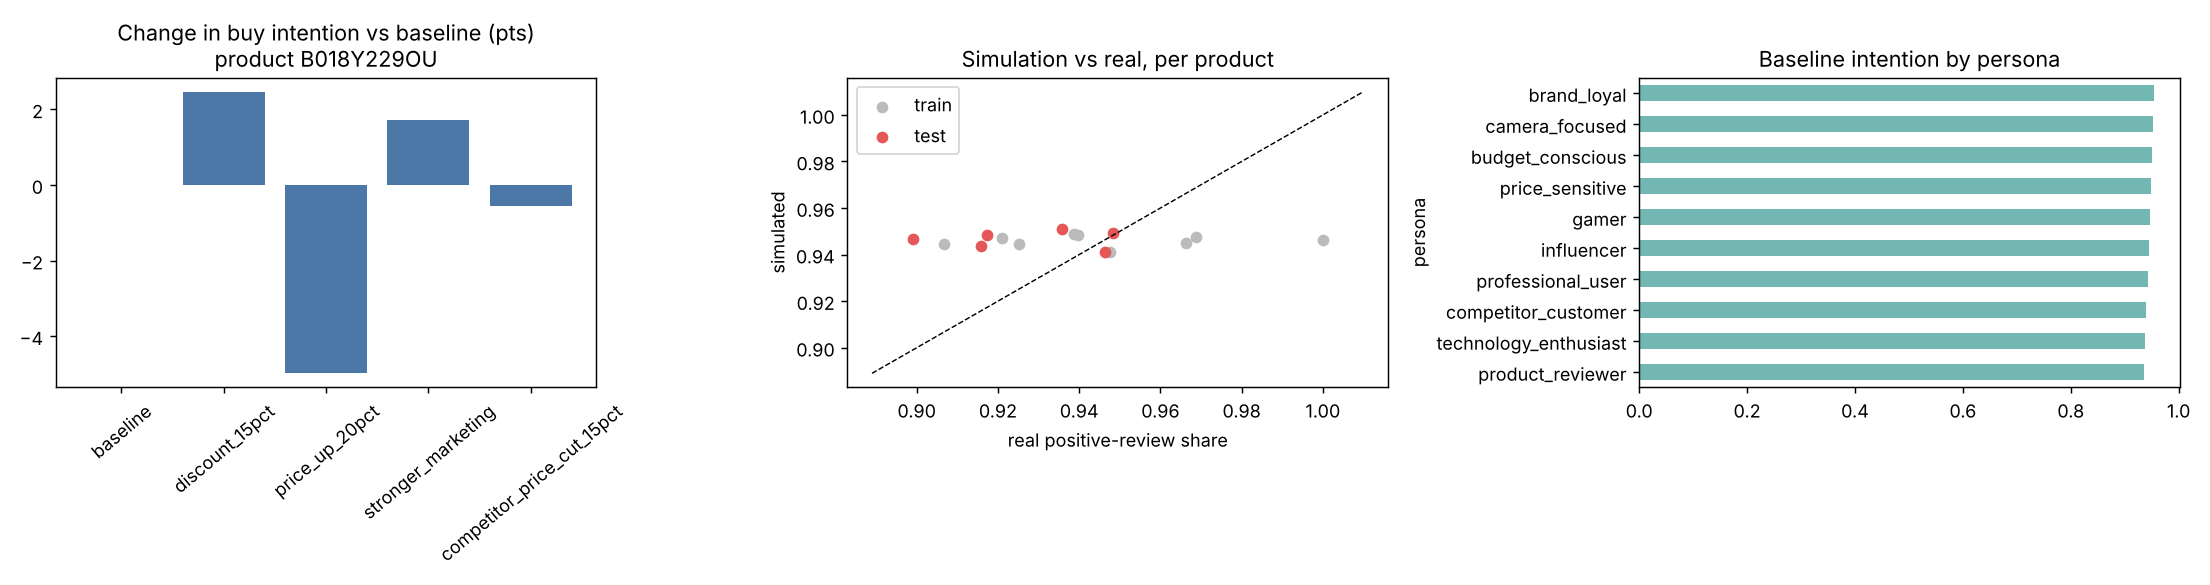

In [4]:
S = pd.read_csv("outputs/scenario_summary.csv")
display(S[["scenario","product","buy_intention","delta_vs_baseline_pts","category_delta_pts"]])
display(Image("outputs/results.png"))

### How to read these results
* **The directions make sense:** a discount raises simulated intention, a price rise lowers it, marketing raises it, and a competitor price cut lowers it slightly.
* **The sizes are produced by our assumed parameters**, not learned from data. They show how the model behaves under those assumptions. They are *not* estimates of real market effects.
* **Ceiling effect:** about nine in ten reviews are positive, so baseline intention is already very high and changes look small.
* **Middle plot (simulation vs real):** the simulated values stay almost flat while the real positive shares vary. This is the symptom explained in the next notebook: the fitted signal strength is zero, so the model treats all products alike.

## Try your own what-if
The cell below runs a single custom scenario in code (the dashboard does the same with sliders: `python src/app.py`).

In [5]:
import numpy as np
from loaders import load_state, calibrate_b0
from simulate import make_agents, simulate

S_ = load_state(".")                                    # reads the Phase-3 outputs
pid = S_["ref"].sort_values("n_reviews", ascending=False).product_id.iat[0]
ag = make_agents(S_["personas"], 400, np.random.default_rng(7))
b0 = calibrate_b0(S_, ag, k=0)
args = (S_["SAT"][pid], S_["G"], S_["NUDGE"][pid], 0, b0)

base = simulate(ag, *args, SCENARIOS["baseline"]).mean()
mine = simulate(ag, *args, dict(price=1.10, marketing=0.5, comp=1.0)).mean()      # +10% price, medium marketing
print(f"baseline {base:.1%}  ->  +10% price & marketing 0.5: {mine:.1%}  ({(mine-base)*100:+.2f} points)")

baseline 93.6%  ->  +10% price & marketing 0.5: 92.6%  (-1.07 points)


**Next:** `04_evaluation.ipynb` asks the hard question: does this simulator actually predict anything about real products?